# openeo_mountains_snow tutorial: from Sentinel-2 to snow water equivalent

This notebook shows how to use `openeo_mountains_snow` on the Copernicus Data Space Ecosystem (CDSE). It produces every important intermediate product and ends with a small validity assessment. It runs on a small area (1.5 x 1.5 km at the Echaurren Norte glacier, Maipo basin, central Chilean Andes) for the southern-hemisphere melt season Sep 2023 - Feb 2024, so it is cheap. The hosted glacier mask covers this part of the Andes.

> **Caveat: reduced scope compared to the original method.** The original SnowFLAKES / dailyHR_SCA / SWE_reconstruction chain works on a multi-year archive: the snow history and the conditional probabilities used to fill cloudy days come from all years (up to 800 scenes), and SWE is reconstructed over full hydrological years (from 1 April in the south). Here a single openEO job can cover at most about half a year, so:
> - history and conditional probabilities are built from this half year only, so fewer similar scenes and noisier probabilities, and more pixels stay unknown (205);
> - SWE only sees accumulation inside the window: snow that fell before September is credited to the accumulation days inside the window, and pixels that do not melt out before the end stay NaN;
> - results are a demonstration of the chain, not a validated product. Compare with the original multi-year run before using the numbers.
>
> **Caveat: GAM step not ported.** The original SCA reconstruction ends with a GAM fit (`run_gam`) that fills the pixels still unknown after the history and probability steps. That step is not in this port, so those pixels stay 205 (and SWE is NaN there).
>
> **Caveat: one-class scenes.** When a Sentinel-2 scene has training pixels of only one class (fully snow-covered or snow-free), every clear pixel gets that class (100 or 0). SnowFLAKES instead borrows the closest model from another scene. We know about this difference. We do it for now to avoid a large number of NaN values, which would also be unwanted.

| # | Function | Product |
|---|---|---|
| 1 | `snow_cover_fraction_cube` | Sentinel-2 snow cover fraction (SCF, 0-100 %, SnowFLAKES representative pixels, 10 m) |
| 2 | `snow_map_from_snow_cover_fraction` | 20 m snow map: 0 no snow, 100 snow, 205 cloud/unknown |
| 3 | `create_modis_snow_cover_fraction_cube` | MODIS SCF (500 m): low-resolution daily reference |
| 4 | `conditional_probability_inputs` | per-pixel probability of snow for each low-resolution SCF range (`cp_*`, `occ_*`) |
| 5 | `snow_cover_area_cube` | daily gap-filled snow cover area (SCA), 0 / 100 / 205 |
| 6 | `swe_meteo_cube` | AGERA5 meteo downscaled to the DEM: temperature, precipitation, shortwave |
| 7 | `snow_water_equivalent_cube` | daily snow water equivalent (SWE, mm) |

### How to run — launch only
Every launch cell creates and starts a batch job and returns immediately. The notebook **does not block, poll, or wait** for a job to finish. This is intentional: job IDs remain available for later comparison and reruns.

Run the launch cells in this order:
1. **Independent jobs:** SCF, MODIS and meteo can be started immediately; the terrain/validity job can also be started immediately.
2. **Snow map:** start only after the SCF job is finished, because it loads the finished SCF result.
3. **CP/occ and SCA:** start after the snow map is finished, because both load the finished snow-map job.
4. **SWE:** start after the SCA job is finished, because it loads the finished SCA result.

Each launch cell exposes the job object (`scf_job`, `modis_job`, `meteo_job`, `snow_job`, `cp_job`, `sca_job`, `swe_job` or `terrain_job`). Run the inspect cell only after that job is finished. After a kernel restart, reconnect with `connection.job('j-...')`. Running a launch cell again creates another job.

**Cost:** the SCF job is the expensive one (a few hundred credits). The others are small.

**Your own area:** change `EXTENT` (UTM, aligned to the 500 m MODIS grid) and `PERIOD` below (at most about six months); the processing grid follows the UTM zone of `EXTENT`. Outside the glacier mask (lon -71.6..-68.6, lat -37.8..-27.1) set `cfg.glacier_mask.stac_url = None` in section 1. Processing constants (thresholds, resolutions, UDFs) are in `src/openeo_mountains_snow/config.py`. `src/openeo_mountains_snow/main.py` builds the whole chain as one job.


In [ ]:
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import openeo
import pandas as pd
import xarray as xr
from IPython.display import display
from pyproj import Transformer
from shapely.geometry import box
from shapely.ops import transform

from openeo_mountains_snow.config import BACKEND, JOB_OPTIONS, build_scf_config, utm_epsg
from openeo_mountains_snow.snow_cover_area.conditional_probability import create_modis_snow_cover_fraction_cube
from openeo_mountains_snow.snow_cover_area.snow_cover_area import conditional_probability_inputs, snow_cover_area_cube
from openeo_mountains_snow.snow_cover_area.snow_map import snow_map_from_snow_cover_fraction
from openeo_mountains_snow.snow_cover_fraction.snow_cover_fraction import snow_cover_fraction_cube
from openeo_mountains_snow.snow_water_equivalent.snow_water_equivalent import (
    basin_snow_cover_area, snow_water_equivalent_cube, swe_meteo_cube,
)

# Echaurren Norte glacier (Maipo basin, Chile), 1.5 x 1.5 km = 3 x 3 MODIS pixels on the 500 m grid.
# 3320-4180 m, 22 % glacier (RGI 7.0). A WGMS reference glacier, close to the Laguna Negra snow station.
EXTENT = {'west': 393500.0, 'south': 6281500.0, 'east': 395000.0, 'north': 6283000.0, 'crs': 'EPSG:32719'}
PERIOD = ['2023-09-01', '2024-03-01']  # southern-hemisphere melt season (max ~6 months per job), end exclusive
EPSG = utm_epsg(EXTENT)  # processing grid (UTM zone of the AOI)
AOI = transform(Transformer.from_crs(EXTENT['crs'], 'EPSG:4326', always_xy=True).transform,
                box(EXTENT['west'], EXTENT['south'], EXTENT['east'], EXTENT['north']))  # SCF step wants WGS84
SOUTH = AOI.centroid.y < 0  # seasons and pole-facing slopes flip in the southern hemisphere
OUT = ROOT / 'tmp' / 'tutorial'  # downloaded results

# Python UDFs run in the executors' memory overhead; the Sentinel-2 SCF chain needs the most.
print(JOB_OPTIONS)

connection = openeo.connect(BACKEND, auto_validate=False).authenticate_oidc()


C:\Users\VROMPAYH\AppData\Local\Temp\ipykernel_18696\247168422.py:32: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  AOI = transform(Transformer.from_crs(EXTENT['crs'], 'EPSG:4326', always_xy=True).transform,


{'executor-memory': '8G', 'executor-memoryOverhead': '8G', 'executor-cores': 1, 'driver-memory': '2G', 'driver-memoryOverhead': '2G', 'python-memory': 'disable', 'max-executors': 8}
Authenticated using refresh token.


In [5]:
def read(job, name):
    """Download the results of a finished job once (to tmp/tutorial/<name>) and open them as an xarray Dataset."""
    target = OUT / name
    if not list(target.glob('*.nc')) + list(target.glob('*.tif')):
        job.get_results().download_files(target)
    ncs, tifs = sorted(target.glob('*.nc')), sorted(target.glob('*.tif'))
    if ncs:
        opened = [xr.open_dataset(p, mask_and_scale=False) for p in ncs]
        try:
            ds = opened[0] if len(opened) == 1 else xr.combine_by_coords(opened)
            return ds.drop_vars('crs', errors='ignore').load()
        finally:
            for ds_part in opened:
                ds_part.close()
    import rasterio  # GTiff results: one file per date, band names in the descriptions
    parts = []
    for f in tifs:
        with rasterio.open(f) as src:
            a, t = src.read(), src.transform
            names = [d or f'band_{i + 1}' for i, d in enumerate(src.descriptions)]
        part = xr.Dataset({n: (('y', 'x'), a[i]) for i, n in enumerate(names)},
                          coords={'x': t.c + t.a * (np.arange(a.shape[2]) + 0.5), 'y': t.f + t.e * (np.arange(a.shape[1]) + 0.5)})
        date = re.search(r'\d{4}-\d{2}-\d{2}', f.name)
        parts.append(part.expand_dims(t=[pd.Timestamp(date.group())]) if date else part)
    return xr.concat(parts, 't') if len(parts) > 1 else parts[0]


def band(ds):
    """First data variable of a result as a (t, y, x) DataArray."""
    return ds[list(ds.data_vars)[0]].transpose('t', 'y', 'x')

## 1. Sentinel-2 snow cover fraction

`snow_cover_fraction_cube` runs the SnowFLAKES step on Sentinel-2 L1C:
- cloud/water mask (OmniCloudMask, WorldCover water);
- local solar incidence angle and terrain-shadow mask;
- glacier mask (RGI 7.0, 10 m): glacier pixels are left out of the shadow training samples, as in SnowFLAKES;
- the representative-pixels UDF, which trains an SVM per scene on clear snow / snow-free pixels and estimates the fraction of snow in every 10 m pixel.

Values 0-100 are SCF (%); values above 100 (e.g. 205, 255) are masked or unclassified pixels.

The result is saved as GTiff because the next step loads it with `load_stac_from_job`, which cannot read netCDF job results on CDSE.


In [ ]:
cfg = build_scf_config()  # includes the hosted glacier mask (Andes, RGI 7.0)

scf_cube = snow_cover_fraction_cube(AOI, PERIOD, connection, cfg)
scf_job = scf_cube.create_job(title='tutorial_scf', out_format='GTiff', job_options=JOB_OPTIONS)
scf_job.start()
scf_job


0:00:00 Job 'j-26112012410445f3a95234943a06c42f': send 'start'
0:00:03 Job 'j-26112012410445f3a95234943a06c42f': created (progress 0%)
0:00:08 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:00:16 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:00:24 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:00:34 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:00:46 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:01:02 Job 'j-26112012410445f3a95234943a06c42f': queued (progress 0%)
0:01:21 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0:01:45 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0:02:15 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0:02:53 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0:03:40 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0:04:39 Job 'j-26112012410445f3a95234943a06c42f': running (progress N/A)
0

<BatchJob job_id='j-26112012410445f3a95234943a06c42f'>

74 Sentinel-2 dates, {'t': 74, 'y': 154, 'x': 154}; dates with >= 50 % valid pixels: 41


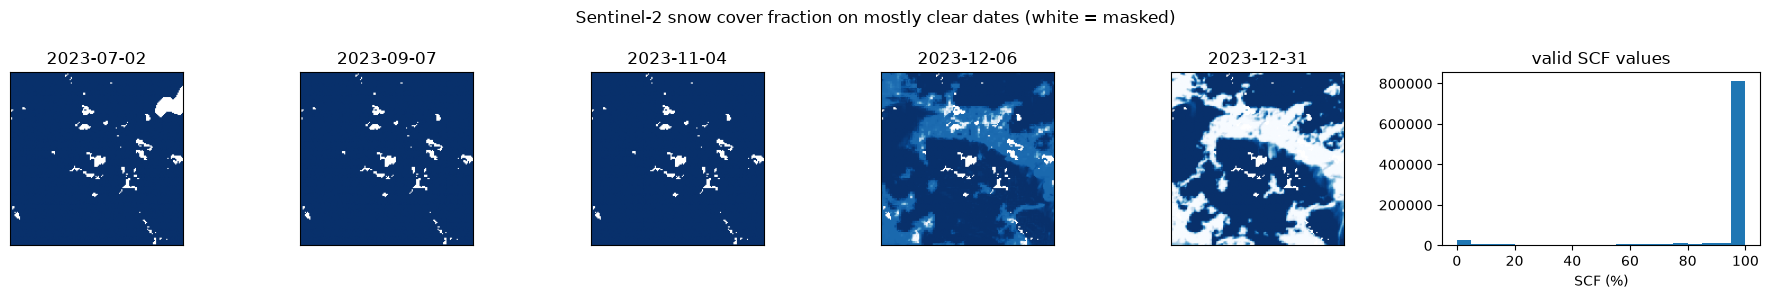

In [7]:
scf = band(read(scf_job, 'scf')).astype(float)
scf_valid = scf <= 100
scf_clear = scf_valid.mean(['x', 'y'])
print(f'{scf.sizes["t"]} Sentinel-2 dates, {dict(scf.sizes)}; dates with >= 50 % valid pixels: {int((scf_clear >= 0.5).sum())}')

fig, axes = plt.subplots(1, 6, figsize=(18, 3), gridspec_kw={'width_ratios': [1, 1, 1, 1, 1, 1.5]})
dates = scf.t.values[scf_clear.values >= 0.5]
for ax, t in zip(axes[:5], dates[np.linspace(0, len(dates) - 1, 5).astype(int)] if len(dates) else []):
    ax.imshow(scf.sel(t=t).where(scf_valid.sel(t=t)), cmap='Blues', vmin=0, vmax=100)
    ax.set_title(str(t)[:10]); ax.set_xticks([]); ax.set_yticks([])
axes[5].hist(scf.values[scf_valid.values], bins=20, color='tab:blue')
axes[5].set_xlabel('SCF (%)'); axes[5].set_title('valid SCF values')
fig.suptitle('Sentinel-2 snow cover fraction on mostly clear dates (white = masked)')
plt.tight_layout()

## 2. Snow map

`snow_map_from_snow_cover_fraction` resamples the SCF to 20 m and binarizes it: SCF > 15 % (`SNOW_FRACTION_THRESHOLD`, as in the original dailyHR_SCA) is snow (100), 15 % or less is no snow (0), masked is 205. This is the high-resolution input of the SCA reconstruction.

**Launch when `scf_job` has finished.**


In [9]:
snow_cube = snow_map_from_snow_cover_fraction(connection.load_stac_from_job(scf_job), crs=EPSG)
snow_job = snow_cube.create_job(title='tutorial_snow', out_format='GTiff', job_options=JOB_OPTIONS)
snow_job.start()
snow_job


bands_from_stac_collection: consulting items for band metadata


<BatchJob job_id='j-26112014110740b98e864d30d2b9f24d'>

74 dates, {'t': 74, 'y': 77, 'x': 77}; dates with any clear pixel: 51


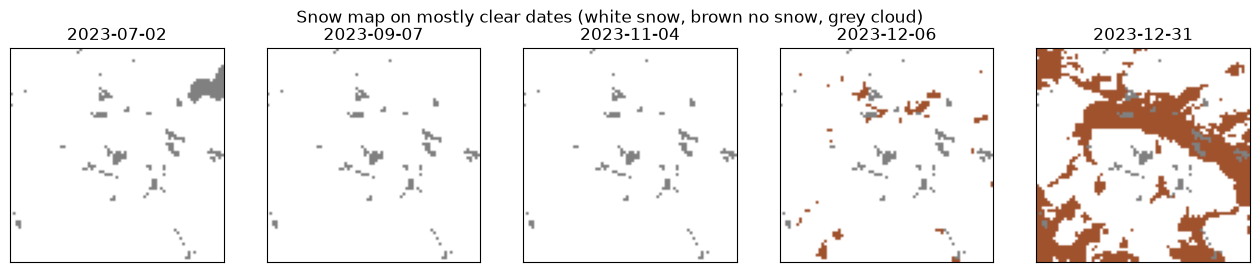

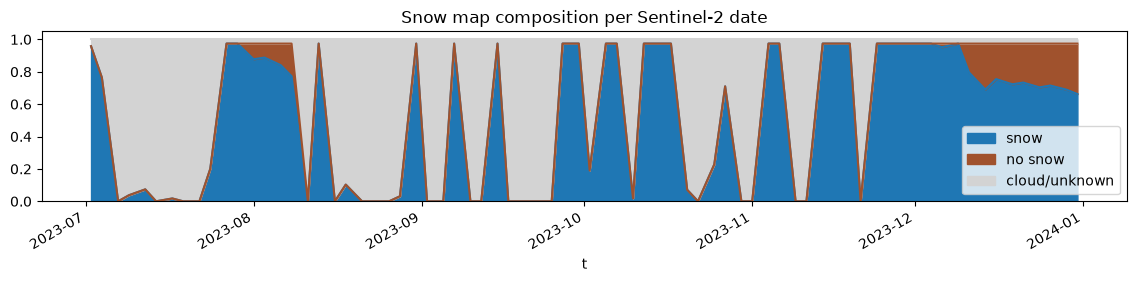

In [10]:
snow = band(read(snow_job, 'snow'))
share = pd.DataFrame({'snow': (snow == 100).mean(['x', 'y']), 'no snow': (snow == 0).mean(['x', 'y']),
                      'cloud/unknown': (snow == 205).mean(['x', 'y'])}, index=snow.t.to_index())
print(f'{snow.sizes["t"]} dates, {dict(snow.sizes)}; dates with any clear pixel: {int((share["cloud/unknown"] < 1).sum())}')

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
clear_dates = share.index[share['cloud/unknown'] < 0.5]
for ax, t in zip(axes, clear_dates[np.linspace(0, len(clear_dates) - 1, 5).astype(int)] if len(clear_dates) else []):
    ax.imshow(snow.sel(t=t), cmap=plt.matplotlib.colors.ListedColormap(['sienna', 'white', 'grey']),
              norm=plt.matplotlib.colors.BoundaryNorm([-1, 50, 150, 256], 3))
    ax.set_title(f'{t:%Y-%m-%d}'); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Snow map on mostly clear dates (white snow, brown no snow, grey cloud)')
share.plot.area(figsize=(14, 2.5), title='Snow map composition per Sentinel-2 date', color=['tab:blue', 'sienna', 'lightgrey']);

## 3. MODIS snow cover fraction

`create_modis_snow_cover_fraction_cube` loads MOD10A1 NDSI snow cover (Terra, ~10:30 local time; Sentinel-2 passes at ~10:20), converts NDSI to SCF (0-100 %, 205 = cloud/flag) and puts it on the 20 m grid. It gives the reconstruction a daily, coarse view of the snow, and it is our independent reference for the Sentinel-2 snow map. `snow_cover_area_cube` builds it internally; this job only exports it for inspection.

In [12]:
modis_cube = create_modis_snow_cover_fraction_cube(connection, PERIOD, EXTENT)
modis_job = modis_cube.create_job(title='tutorial_modis_scf', out_format='netCDF', job_options=JOB_OPTIONS)
modis_job.start()
modis_job

<BatchJob job_id='j-2611201510574a978576ef5bcca61bf3'>

81 MODIS dates in ['2023-07-01', '2024-01-01'], of which >= 50 % clear: 43


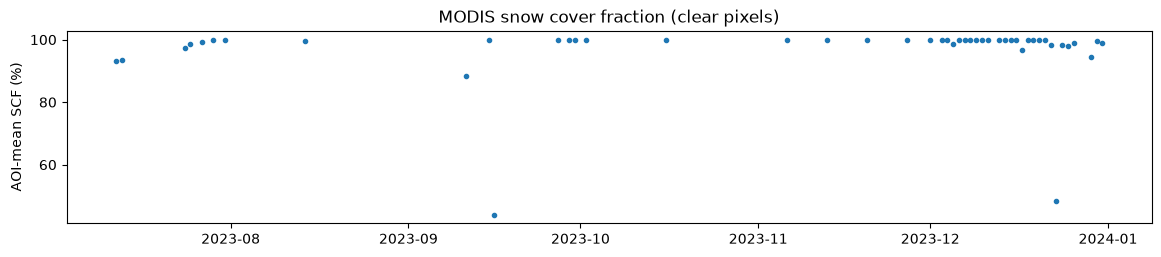

In [13]:
modis = band(read(modis_job, 'modis_scf'))
modis_clear = (modis <= 100).mean(['x', 'y'])
print(f'{modis.sizes["t"]} MODIS dates in {PERIOD}, of which >= 50 % clear: {int((modis_clear >= 0.5).sum())}')
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.plot(modis.t, modis.where(modis <= 100).mean(['x', 'y']), 'o', ms=3)
ax.set_ylabel('AOI-mean SCF (%)'); ax.set_title('MODIS snow cover fraction (clear pixels)');

## 4. Conditional probabilities

`conditional_probability_inputs` averages the snow map onto the 500 m grid (a low-resolution SCF) and splits it into SCF ranges (10 % steps, 10 % buffer). For every 20 m pixel and range it counts:
- `occ_<range>`: on how many days the low-resolution SCF was in that range;
- `cp_<range>`: on which share of those days the pixel was snow.

The reconstruction uses `cp` to decide which pixels are snow when only the coarse SCF is known. `snow_cover_area_cube` computes these internally; this job only exports them for inspection.

**Launch when `snow_job` has finished.**

In [14]:
cp_cube = conditional_probability_inputs(connection, connection.load_stac_from_job(snow_job), EXTENT, PERIOD)
cp_job = cp_cube.create_job(title='tutorial_cp_occ', out_format='netCDF', job_options=JOB_OPTIONS)
cp_job.start()
cp_job

bands_from_stac_collection: consulting items for band metadata


<BatchJob job_id='j-261120152058456b9a104802fe9fe909'>

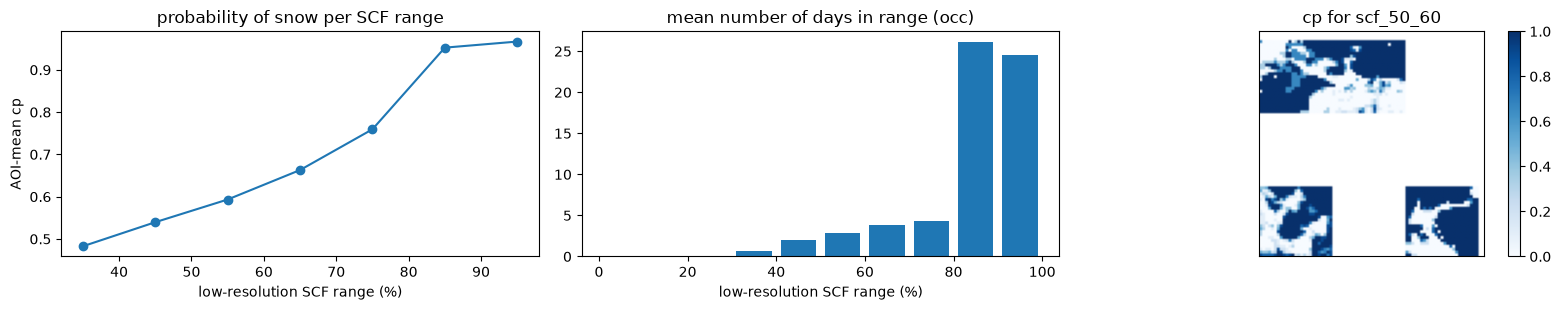

In [15]:
cp_ds = read(cp_job, 'cp_occ').squeeze(drop=True)
ranges = [v[3:] for v in cp_ds.data_vars if v.startswith('cp_')]  # e.g. 'scf_0_10'
mid = np.array([np.mean([float(x) for x in r.split('_')[1:]]) for r in ranges])
cp_mean = np.array([float(cp_ds[f'cp_{r}'].mean()) for r in ranges])
occ_mean = np.array([float(cp_ds[f'occ_{r}'].mean()) for r in ranges])

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2))
axes[0].plot(mid, cp_mean, 'o-'); axes[0].set_xlabel('low-resolution SCF range (%)'); axes[0].set_ylabel('AOI-mean cp')
axes[0].set_title('probability of snow per SCF range')
axes[1].bar(mid, occ_mean, width=8); axes[1].set_xlabel('low-resolution SCF range (%)'); axes[1].set_title('mean number of days in range (occ)')
pick = ranges[len(ranges) // 2]
im = axes[2].imshow(cp_ds[f'cp_{pick}'], cmap='Blues', vmin=0, vmax=1); plt.colorbar(im, ax=axes[2])
axes[2].set_title(f'cp for {pick}'); axes[2].set_xticks([]); axes[2].set_yticks([])
plt.tight_layout()

## 5. Snow cover area reconstruction

`snow_cover_area_cube` merges the snow map, the MODIS SCF and the conditional probabilities and runs the reconstruction UDF. The UDF fills cloudy and missing days. Output: one map per day, 0 / 100 / 205. Saved as GTiff because the SWE step loads it.

Caveat: the history and probabilities come from this half year only (see the intro), and the final GAM gap-filling step of the original is not ported. Pixels still unknown after the history and probability steps stay 205.

**Launch when `snow_job` has finished.**


In [17]:

sca_cube = snow_cover_area_cube(connection, connection.load_stac_from_job(snow_job), EXTENT, PERIOD)
sca_job = sca_cube.create_job(title='tutorial_sca', out_format='GTiff', job_options=JOB_OPTIONS)
sca_job.start()
sca_job

bands_from_stac_collection: consulting items for band metadata


<BatchJob job_id='j-2611201533404133842bd5afbaa55b5b'>

118 SCA dates; time steps (days): {1: 67, 2: 35, 3: 15}


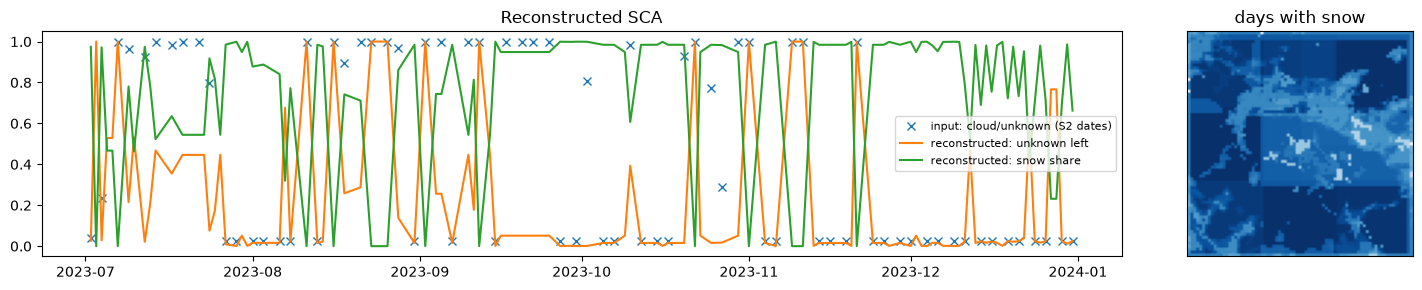

In [18]:
sca = band(read(sca_job, 'sca'))
steps = pd.Series(np.diff(sca.t.values).astype('timedelta64[D]').astype(int)).value_counts().sort_index()
print(f'{sca.sizes["t"]} SCA dates; time steps (days): {steps.to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(15, 3), gridspec_kw={'width_ratios': [3, 1]})
axes[0].plot(snow.t, (snow == 205).mean(['x', 'y']), 'x', label='input: cloud/unknown (S2 dates)')
axes[0].plot(sca.t, (sca == 205).mean(['x', 'y']), label='reconstructed: unknown left')
axes[0].plot(sca.t, (sca == 100).mean(['x', 'y']), label='reconstructed: snow share')
axes[0].legend(fontsize=8); axes[0].set_title('Reconstructed SCA')
axes[1].imshow((sca == 100).sum('t'), cmap='Blues'); axes[1].set_title('days with snow'); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout()

## 6. Downscaled meteo

`swe_meteo_cube` brings daily AGERA5 to the 30 m Copernicus DEM:
- **temperature** (°C): lapse-rate correction from the ERA5 reference height (geopotential) to the DEM, monthly rates per hemisphere;
- **precipitation** (mm/day): bilinear resampling;
- **shortwave** (W/m²): daily mean flux corrected for slope, aspect and sun position (solar-position and incidence-angle UDFs).

`snow_water_equivalent_cube` builds it internally; this job only exports it for inspection.

In [19]:
meteo_cube = swe_meteo_cube(connection, EXTENT, PERIOD[0], PERIOD)
meteo_job = meteo_cube.create_job(title='tutorial_meteo', out_format='netCDF', job_options=JOB_OPTIONS)
meteo_job.start()
meteo_job

Deriving band listing from unordered `item_assets`
Using 'eo:bands' metadata, but STAC extension eo was not declared.


<BatchJob job_id='j-2611201551094c8e9a30274913d2834e'>

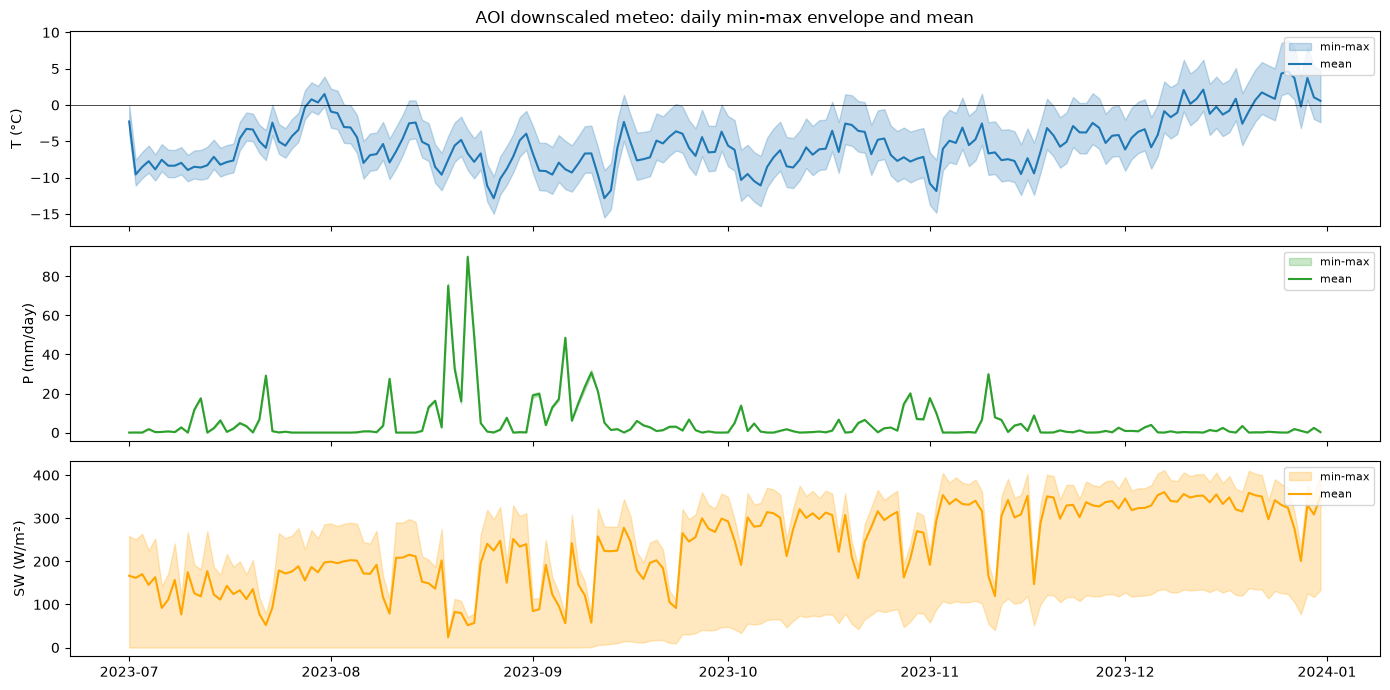

In [20]:
met = read(meteo_job, 'meteo')

# Daily AOI stats for each variable
T = met['temperature_downscaled']
P = met['precipitation']
SW = met['shortwave-radiation-flux-downscaled']

ta_min, ta_mean, ta_max = T.min(['x', 'y']), T.mean(['x', 'y']), T.max(['x', 'y'])
pr_min, pr_mean, pr_max = P.min(['x', 'y']), P.mean(['x', 'y']), P.max(['x', 'y'])
sw_min, sw_mean, sw_max = SW.min(['x', 'y']), SW.mean(['x', 'y']), SW.max(['x', 'y'])

# Keep mean series for downstream cells
ta = ta_mean
pr = pr_mean
sw = sw_mean

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)

axes[0].fill_between(ta_mean.t.values, ta_min.values, ta_max.values, alpha=0.25, color='tab:blue', label='min-max')
axes[0].plot(ta_mean.t, ta_mean, color='tab:blue', lw=1.5, label='mean')
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_ylabel('T (°C)')
axes[0].legend(loc='upper right', fontsize=8)

axes[1].fill_between(pr_mean.t.values, pr_min.values, pr_max.values, alpha=0.25, color='tab:green', label='min-max')
axes[1].plot(pr_mean.t, pr_mean, color='tab:green', lw=1.5, label='mean')
axes[1].set_ylabel('P (mm/day)')
axes[1].legend(loc='upper right', fontsize=8)

axes[2].fill_between(sw_mean.t.values, sw_min.values, sw_max.values, alpha=0.25, color='orange', label='min-max')
axes[2].plot(sw_mean.t, sw_mean, color='orange', lw=1.5, label='mean')
axes[2].set_ylabel('SW (W/m²)')
axes[2].legend(loc='upper right', fontsize=8)

axes[0].set_title('AOI downscaled meteo: daily min-max envelope and mean')
plt.tight_layout()

Text(0.5, 0.98, 'Downscaled meteo 2D diagnostics')

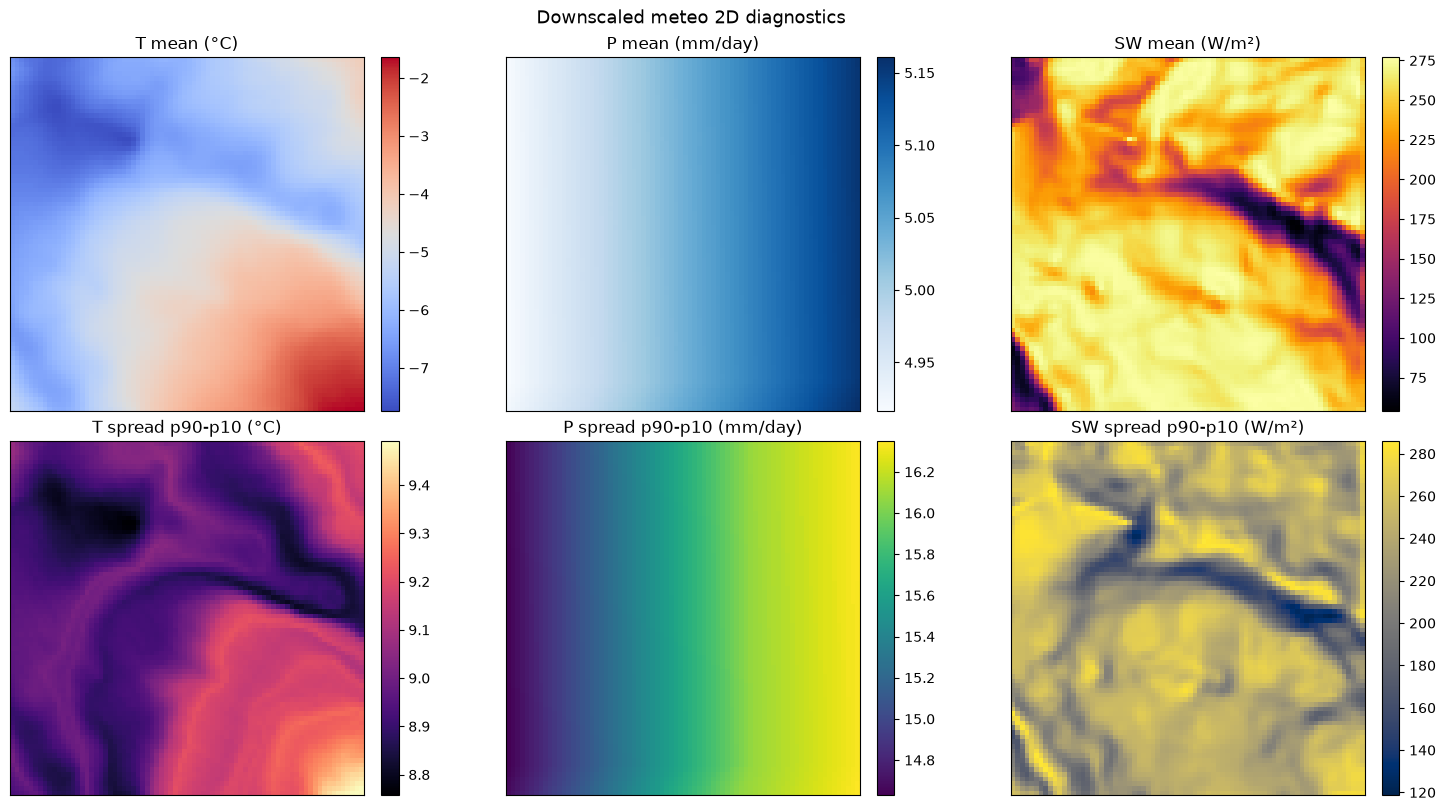

In [21]:
# 2D spatial diagnostics for downscaled meteo (mean and temporal spread)
# Spread = p90 - p10 over time, robust to occasional outliers.

T_mean_map = T.mean('t')
P_mean_map = P.mean('t')
SW_mean_map = SW.mean('t')

T_spread_map = T.quantile(0.9, dim='t') - T.quantile(0.1, dim='t')
P_spread_map = P.quantile(0.9, dim='t') - P.quantile(0.1, dim='t')
SW_spread_map = SW.quantile(0.9, dim='t') - SW.quantile(0.1, dim='t')

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

im = axes[0, 0].imshow(T_mean_map, cmap='coolwarm')
axes[0, 0].set_title('T mean (°C)')
plt.colorbar(im, ax=axes[0, 0], fraction=0.046, pad=0.04)

im = axes[0, 1].imshow(P_mean_map, cmap='Blues')
axes[0, 1].set_title('P mean (mm/day)')
plt.colorbar(im, ax=axes[0, 1], fraction=0.046, pad=0.04)

im = axes[0, 2].imshow(SW_mean_map, cmap='inferno')
axes[0, 2].set_title('SW mean (W/m²)')
plt.colorbar(im, ax=axes[0, 2], fraction=0.046, pad=0.04)

im = axes[1, 0].imshow(T_spread_map, cmap='magma')
axes[1, 0].set_title('T spread p90-p10 (°C)')
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

im = axes[1, 1].imshow(P_spread_map, cmap='viridis')
axes[1, 1].set_title('P spread p90-p10 (mm/day)')
plt.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04)

im = axes[1, 2].imshow(SW_spread_map, cmap='cividis')
axes[1, 2].set_title('SW spread p90-p10 (W/m²)')
plt.colorbar(im, ax=axes[1, 2], fraction=0.046, pad=0.04)

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Downscaled meteo 2D diagnostics', fontsize=13)

## 7. Snow water equivalent

`snow_water_equivalent_cube` merges the SCA with the downscaled meteo and runs the SWE UDF. The UDF works backwards from each melt-out date: it sums the modelled melt (temperature and shortwave) over the snow-covered days and spreads that mass over the accumulation days before.

`basin_sca` is the AOI-mean SCA per day, computed locally from the downloaded SCA (section 5) with `basin_snow_cover_area`. It decides whether snow accumulates on warm days, as in the original method. As in the original, melt is forced to zero for the first 122 days of the hydrological year (from 1 April in the south, 1 October in the north).

Caveat: with a half-year window, snow that accumulated before the window is credited to the accumulation days inside it, and pixels that are still snow-covered at the end have no melt-out date, so their SWE is NaN.

**Launch when `sca_job` has finished and the section 5 inspect cell has run.**


In [23]:

swe_cube = snow_water_equivalent_cube(connection, connection.load_stac_from_job(sca_job), EXTENT, PERIOD,
                                      basin_sca=basin_snow_cover_area(sca))
swe_job = swe_cube.create_job(title='tutorial_swe', out_format='netCDF', job_options=JOB_OPTIONS)
swe_job.start()
swe_job

bands_from_stac_collection: consulting items for band metadata
Deriving band listing from unordered `item_assets`
Using 'eo:bands' metadata, but STAC extension eo was not declared.


<BatchJob job_id='j-2611201821184fd9ad0d0497477f63c2'>

The dashed line is the cumulative snowfall (precipitation on days below 2 °C, from section 6), a rough upper bound for the SWE.

SWE: 184 dates, NaN share 0.84, AOI-mean peak 40 mm on 2023-12-12 | snowfall (T < 2.0 °C) 924 mm


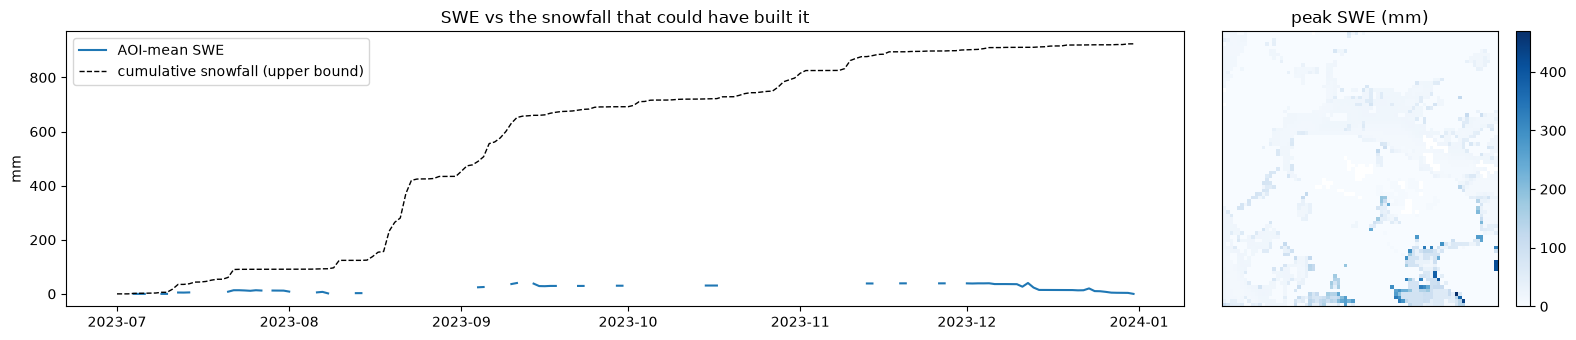

In [24]:
swe = band(read(swe_job, 'swe'))
T_THR = 2.0  # SWE UDF temperature_threshold: precipitation counts as snow below this daily-mean T (°C)
snowfall = pr.where(ta < T_THR, 0)
swe_mean = swe.mean(['x', 'y'])
print(f'SWE: {swe.sizes["t"]} dates, NaN share {float(swe.isnull().mean()):.2f}, AOI-mean peak {float(swe_mean.max()):.0f} mm '
      f'on {str(swe_mean.idxmax().values)[:10]} | snowfall (T < {T_THR} °C) {float(snowfall.sum()):.0f} mm')

fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={'width_ratios': [3, 1]})
axes[0].plot(swe_mean.t, swe_mean, label='AOI-mean SWE')
axes[0].plot(snowfall.t, snowfall.cumsum('t'), 'k--', lw=1, label='cumulative snowfall (upper bound)')
axes[0].set_ylabel('mm'); axes[0].legend(); axes[0].set_title('SWE vs the snowfall that could have built it')
im = axes[1].imshow(swe.max('t'), cmap='Blues'); plt.colorbar(im, ax=axes[1])
axes[1].set_title('peak SWE (mm)'); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout()

## 8. Validity assessment

There is no in-situ data for this AOI, so the checks are of three kinds:
- **Independent sensor:** the Sentinel-2 snow map should agree with MODIS on the same day.
- **Physical pattern:** more snow higher up and on north faces; snow probability should increase with the coarse SCF.
- **Consistency and conservation:** the reconstruction keeps the clear observations and fills the gaps; peak SWE cannot exceed the snowfall before it.

Each check adds a row to the scorecard: PASS / FAIL, or CHECK when there is only a rough literature range. The checks need all products above plus the DEM on the 20 m grid (launch it any time).

In [26]:
terrain_cube = connection.load_collection('COPERNICUS_30', spatial_extent=EXTENT).resample_spatial(
    resolution=20, projection=EPSG, method='bilinear')
terrain_job = terrain_cube.create_job(title='tutorial_terrain', out_format='netCDF', job_options=JOB_OPTIONS)
terrain_job.start()
terrain_job


<BatchJob job_id='j-2611201919264f5dbbd510bfbfb4919f'>

In [ ]:
checks = []


def check(step, name, value, expected, ok):
    checks.append({'step': step, 'check': name, 'value': value, 'expected': expected,
                   'result': 'CHECK' if ok is None else ('PASS' if ok else 'FAIL')})


def spearman(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return pd.Series(a[m]).rank().corr(pd.Series(b[m]).rank())


def on_grid(a, grid):
    """Nearest pixel of `a` for each pixel of the UTM `grid` (a may be on a lat/lon grid)."""
    gx, gy = np.meshgrid(grid.x.values, grid.y.values)
    if abs(float(a.x[0])) < 1000:  # lat/lon
        gx, gy = Transformer.from_crs(f'EPSG:{EPSG}', 'EPSG:4326', always_xy=True).transform(gx, gy)
    pts = dict(x=xr.DataArray(gx, dims=('y', 'x')), y=xr.DataArray(gy, dims=('y', 'x')))
    return a.sel(**pts, method='nearest').assign_coords(x=grid.x.values, y=grid.y.values).astype(float)


# Terrain on the snow grid; aspect = downslope direction, clockwise from north.
dem = read(terrain_job, 'terrain')
elev = on_grid(dem[list(dem.data_vars)[0]].squeeze(drop=True), snow)
dzdy, dzdx = np.gradient(elev.values, 20, 20)  # rows go north -> south
aspect = np.degrees(np.arctan2(-dzdx, dzdy)) % 360
facing = np.where((aspect >= 315) | (aspect < 45), 'north', np.where((aspect >= 135) & (aspect < 225), 'south', 'east/west'))
pole, equator = ('south', 'north') if SOUTH else ('north', 'south')  # pole-facing slopes get less sun
print(f'elevation {float(elev.min()):.0f}..{float(elev.max()):.0f} m | facing: {pd.Series(facing.ravel()).value_counts().to_dict()}')

# 8.1 Snow map vs MODIS on common dates
s2, mo = xr.align(snow, modis, join='inner')
s2_clear, mo_clear = s2.isin([0, 100]), mo <= 100
day = pd.DataFrame({'s2_clear': s2_clear.mean(['x', 'y']), 'mo_clear': mo_clear.mean(['x', 'y']),
                    's2_snow': (s2 == 100).sum(['x', 'y']) / s2_clear.sum(['x', 'y']),
                    'mo_snow': mo.where(mo_clear).mean(['x', 'y']) / 100}, index=s2.t.to_index())
both = day[(day.s2_clear >= 0.5) & (day.mo_clear >= 0.5)]
mo_clear_days = day[day.mo_clear >= 0.5]
lost = mo_clear_days[mo_clear_days.s2_clear < 0.05]
bias, r = (both.s2_snow - both.mo_snow).mean(), both.s2_snow.corr(both.mo_snow)
check('snow map', 'snow fraction vs MODIS: bias', f'{bias:+.2f} (n={len(both)})', '|bias| < 0.15', abs(bias) < 0.15)
check('snow map', 'snow fraction vs MODIS: correlation', f'r = {r:.2f}', 'r > 0.7', r > 0.7)
check('snow map', 'S2 all cloud while MODIS clear', f'{len(lost)} / {len(mo_clear_days)} days', '< 20 %', len(lost) < 0.2 * len(mo_clear_days))

# 8.2 Physical patterns of the snow map in spring (Sep-Nov south, Mar-May north)
spring = snow.sel(t=snow.t.dt.month.isin([9, 10, 11] if SOUTH else [3, 4, 5]))
freq = (spring == 100).sum('t') / spring.isin([0, 100]).sum('t')  # per-pixel snow frequency of clear obs
by_band = freq.groupby(((elev // 100) * 100).rename('band')).mean()
by_face = pd.Series(freq.values.ravel()).groupby(facing.ravel()).mean()
rho = spearman(by_band.band.values.astype(float), by_band.values)
check('snow map', 'spring snow increases with elevation', f'rank corr {rho:.2f}', '> 0', rho > 0)
check('snow map', f'spring snow {pole}-facing > {equator}-facing',
      f'{pole} {by_face.get(pole, np.nan):.2f} / {equator} {by_face.get(equator, np.nan):.2f}',
      'pole-facing > equator-facing', by_face.get(pole, 0) > by_face.get(equator, 0))

# 8.3 Conditional probabilities
rho_cp = spearman(mid, cp_mean)
cp_all = np.concatenate([cp_ds[f'cp_{r}'].values.ravel() for r in ranges])
cp_all = cp_all[np.isfinite(cp_all)]
check('cond. prob.', 'cp increases with SCF range', f'rank corr {rho_cp:.2f}', '> 0.9', rho_cp > 0.9)
check('cond. prob.', 'cp within [0, 1]', f'{cp_all.min():.2f}..{cp_all.max():.2f}', '0..1', cp_all.min() >= 0 and cp_all.max() <= 1)

# 8.4 SCA reconstruction
sca_on, s2_on = xr.align(sca, snow, join='inner')
fidelity = float((sca_on == s2_on).where(s2_on.isin([0, 100])).mean())
unknown_in, unknown_out = float((~snow.isin([0, 100])).mean()), float((sca == 205).mean())
v = sca.where(sca != 205).ffill('t').values
flips = ((np.diff(v, axis=0) != 0) & np.isfinite(np.diff(v, axis=0))).sum(0)
check('SCA', 'keeps clear S2 observations', f'{fidelity:.4f}', '1.0', fidelity > 0.999)
check('SCA', 'unknown (205) left', f'{unknown_out:.2f} (S2 input {unknown_in:.2f})', '< 0.10', unknown_out < 0.10)
check('SCA', 'daily, gap-free time axis', f'{steps.to_dict()}', 'all steps 1 day', list(steps.index) == [1])
check('SCA', 'snow/no-snow flips per pixel', f'median {np.median(flips):.0f}', '<= 6', np.median(flips) <= 6)

# 8.5 SWE
sf_before = float(snowfall.sel(t=slice(None, swe_mean.idxmax().values)).sum())
peak_px = on_grid(swe.max('t'), snow)
rho_swe = spearman(elev.values.ravel(), peak_px.values.ravel())
check('SWE', 'NaN share', f'{float(swe.isnull().mean()):.2f}', '< 0.05', float(swe.isnull().mean()) < 0.05)
check('SWE', 'mass: AOI peak <= snowfall before peak', f'{float(swe_mean.max()):.0f} / {sf_before:.0f} mm', '<= 1', float(swe_mean.max()) <= sf_before)
check('SWE', 'AOI-mean peak SWE', f'{float(swe_mean.max()):.0f} mm', '~300-1500 mm (central Andes >3300 m, rough)', None)
check('SWE', 'peak SWE increases with elevation', f'rank corr {rho_swe:.2f}', '> 0', rho_swe > 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
im = axes[0].imshow(elev, cmap='terrain'); axes[0].set_title('elevation (m)'); plt.colorbar(im, ax=axes[0])
axes[1].scatter(both.mo_snow, both.s2_snow); axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('MODIS snow fraction'); axes[1].set_ylabel('S2 snow fraction'); axes[1].set_title(f'S2 vs MODIS (n={len(both)})')
im = axes[2].imshow(freq, cmap='Blues', vmin=0, vmax=1); axes[2].set_title('spring snow frequency (S2)'); plt.colorbar(im, ax=axes[2])
for ax in (axes[0], axes[2]):
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

score = pd.DataFrame(checks)
print(score.result.value_counts().to_dict())
with pd.option_context('display.max_colwidth', None):
    display(score)


### How to read the scorecard

- **snow map vs MODIS:** MODIS pixels are 500 m and see the terrain differently, so a small bias is normal. A large negative bias or many "S2 all cloud while MODIS clear" days point at an over-eager cloud/shadow mask or at scenes where the SVM found only one class.
- **physical patterns:** with only 10 x 10 MODIS pixels, a weak or missing trend is a warning, not proof of an error. Repeat on a larger AOI before drawing conclusions.
- **conditional probability:** cp must rise with the coarse SCF. If it does not, the snow map or the range masks are wrong, and the reconstruction will be too.
- **SCA:** the reconstruction must not change clear observations and should leave few unknown pixels. Many flips per pixel mean noisy gap filling.
- **SWE:** peak SWE above the snowfall before it breaks mass conservation (or the snowfall threshold is off). The peak magnitude is only a rough plausibility check; compare with the Laguna Negra / Echaurren in-situ records (DGA Chile) for a real validation.
